# Buổi 5 · Tình huống 02 — Quyết định tưới cây (Adaline)

Notebook này dùng lại bối cảnh trong [`bai-tap/buoi4-tinh-huong/02_tuoi_cay_tu_dong.py`](../../bai-tap/buoi4-tinh-huong/02_tuoi_cay_tu_dong.py), nhưng thay Perceptron (0/1) bằng **Adaline** học quy tắc Widrow–Hoff (LMS) với **target liên tục**.

Không có dữ liệu hoặc lời giải dựng sẵn trong notebook này. Các code cell chỉ chứa comment định hướng; bạn tự thu thập dữ liệu, xử lý, huấn luyện, đánh giá và triển khai thử.

In [89]:
import os

print("Thư mục notebook đang chạy:")
print(os.getcwd())

print("\nCác file/thư mục hiện có:")
print(os.listdir())

Thư mục notebook đang chạy:
d:\AI\Documents\Downloads\lac-hong-neural-network

Các file/thư mục hiện có:
['.git', '.gitignore', '.vscode', 'bai-tap', 'data', 'Git-command.txt', 'ket_qua_test_tuoi_cay.csv', 'LICENSE', 'LIST-DE-TAI.md', 'notebooks', 'README.md', 'requirements.txt', 'SETUP.md']


## Bối cảnh

Một bộ điều khiển đơn giản cần quyết định có bật máy bơm tưới cây hay không.

Feature có thể cân nhắc: độ ẩm đất, nhiệt độ không khí, số giờ từ lần tưới gần nhất, khả năng có mưa (đã chuẩn hoá).

## Vì sao dùng Adaline thay Perceptron?

Thay vì chỉ 0/1 (chưa cần tưới / cần tưới), hãy coi target là **mức độ cần nước** trong [0, 1], hoặc trực tiếp là **số phút nên tưới** (một số thực không âm) — Adaline phù hợp để học một giá trị liên tục như vậy.

Nhắc lại công thức Adaline / Widrow–Hoff:

$$
\text{net} = \mathbf{w}^\top \mathbf{x} + b, \qquad e = t - \text{net}
$$

$$
\mathbf{w} \leftarrow \mathbf{w} + \eta e \mathbf{x}, \qquad b \leftarrow b + \eta e
$$

So sánh với việc chỉ dùng Perceptron trả lời có/không: target liên tục giúp bộ điều khiển biết nên tưới bao lâu, không chỉ tưới hay không.

## Nhiệm vụ suy nghĩ

1. Xác định feature nào làm nhu cầu tưới tăng hoặc giảm, và chọn thang đo target (điểm 0–1 hay số phút tưới).
2. Tự tạo tối thiểu 20 mẫu, tránh tạo tất cả mẫu theo một quy tắc quá hiển nhiên.
3. Dự đoán bằng tay net = wᵀx + b cho một mẫu trước khi cho Adaline chạy.
4. Huấn luyện Adaline bằng Widrow–Hoff, xem trọng số học được và đối chiếu với trực giác.
5. Đề xuất một trường hợp mà quan hệ tuyến tính giữa feature và nhu cầu tưới có thể chưa đủ tốt.

Không có code mẫu hoặc lời giải trong notebook này. Bắt đầu phần triển khai ở các cell dưới.

## 1. Thu thập / tạo dữ liệu

In [90]:
import numpy as np
import pandas as pd

csv_path = "data/TARP.csv"

df = pd.read_csv(csv_path)

df.columns = df.columns.str.strip()

print("Đọc dữ liệu thành công!")
print(df.head())
# Chọn feature
features = [
    "Soil Moisture",
    "Temperature",
    "Time",
    "rainfall"
]

# Chuyển Status thành target
df["Status"] = (
    df["Status"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"OFF": 0, "ON": 1})
)

df = df.dropna()

X = df[features].values.astype(float)
t = df["Status"].values.astype(float)

print("Số mẫu:", len(X))
print("Feature:", features)

pd.DataFrame(X, columns=features).head()


Đọc dữ liệu thành công!
   Soil Moisture  Temperature  Soil Humidity  Time  Air temperature (C)  \
0             54           22             70    21                19.52   
1             12           20             40   104                19.49   
2             34           26             35    62                19.47   
3              7           44             44    93                19.54   
4             50           38             23    92                19.61   

   Wind speed (Km/h)  Air humidity (%)  Wind gust (Km/h)  Pressure (KPa)  \
0               2.13             55.04              6.30          101.50   
1               2.01             55.17             10.46          101.50   
2               1.90             55.30             14.63          101.51   
3               2.28             54.20             16.08          101.51   
4               2.66             53.09             17.52          101.51   

         ph    rainfall     N     P     K Status  
0  6.502985  202.

,Soil Moisture,Temperature,Time,rainfall
0,54.0,22.0,21.0,202.935536
1,12.0,20.0,104.0,226.655537
2,34.0,26.0,62.0,263.964248
3,7.0,44.0,93.0,242.864034
4,50.0,38.0,92.0,262.717340


## 2. Chuẩn hoá feature
Các feature có đơn vị khác nhau nên được đưa về cùng thang đo trước khi huấn luyện Adaline.

Mô hình sử dụng 4 Feature:

- Soil Moisture: độ ẩm đất
- Temperature: nhiệt độ
- Time: thời gian từ lần tưới trước
- rainfall: lượng mưa

Các Feature có đơn vị và khoảng giá trị khác nhau. Ví dụ, nhiệt độ có thể có giá trị khoảng vài chục, trong khi lượng mưa có thể có giá trị lớn hơn nhiều. Nếu đưa trực tiếp các giá trị này vào Adaline, Feature có thang đo lớn có thể ảnh hưởng mạnh hơn đến quá trình cập nhật trọng số.

Vì vậy, dữ liệu cần được chuẩn hóa trước khi đưa vào mô hình.

Min-Max Scaling đưa giá trị của từng Feature về một thang đo chung, thông thường là khoảng từ 0 đến 1.
Mục đích:

- Đưa các Feature về cùng thang đo.
- Giúp quá trình cập nhật trọng số của Adaline ổn định hơn.
- Hạn chế việc Feature có giá trị lớn chi phối quá trình học.
- Giúp các trọng số của mô hình dễ so sánh hơn.

In [91]:
# Chuẩn hóa Min-Max

X_min = X.min(axis=0)
X_max = X.max(axis=0)

X_scaled = (X - X_min) / (X_max - X_min)

print("Tham số chuẩn hóa:")
for name, mn, mx in zip(features, X_min, X_max):
    print(f"{name}: min={mn}, max={mx}")

X_scaled[:5]


Tham số chuẩn hóa:
Soil Moisture: min=1.0, max=90.0
Temperature: min=0.0, max=45.0
Time: min=0.0, max=110.0
rainfall: min=20.21126747, max=298.5601175


array([[0.59550562, 0.48888889, 0.19090909, 0.65645778],
       [0.12359551, 0.44444444, 0.94545455, 0.74167459],
       [0.37078652, 0.57777778, 0.56363636, 0.87571039],
       [0.06741573, 0.97777778, 0.84545455, 0.79990547],
       [0.5505618 , 0.84444444, 0.83636364, 0.87123073]])

## 3. Tách train/test

Tách dữ liệu trước khi huấn luyện để có thể đánh giá khách quan.

In [92]:
# Chia train/test

np.random.seed(42)

indices = np.random.permutation(len(X_scaled))

split = int(len(X_scaled) * 0.8)

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X_scaled[train_idx]
X_test = X_scaled[test_idx]

t_train = t[train_idx]
t_test = t[test_idx]

print("Train:", len(X_train))
print("Test :", len(X_test))


Train: 1760
Test : 440


## 4. Cài đặt và huấn luyện Adaline

Viết (hoặc tái sử dụng) một bước cập nhật Widrow–Hoff, rồi huấn luyện qua nhiều epoch và theo dõi MSE.

In [93]:
class Adaline:
    def __init__(self, eta=0.01, epochs=100):
        self.eta = eta
        self.epochs = epochs
        self.w = None
        self.b = 0
        self.mse_history = []

    def fit(self, X, t):
        self.w = np.zeros(X.shape[1])
        self.b = 0

        for epoch in range(self.epochs):
            errors = []

            for x_k, target in zip(X, t):
                net = np.dot(self.w, x_k) + self.b
                e = target - net

                self.w += self.eta * e * x_k
                self.b += self.eta * e

                errors.append(e**2)

            self.mse_history.append(np.mean(errors))

        return self

    def predict(self, X):
        return np.dot(X, self.w) + self.b


model = Adaline(eta=0.01, epochs=100)

model.fit(X_train, t_train)

print("Weight:")
for f, w in zip(features, model.w):
    print(f"{f}: {w:.4f}")

print("Bias:", model.b)


Weight:
Soil Moisture: -0.5725
Temperature: 0.5165
Time: -0.4545
rainfall: -0.0299
Bias: 0.7941828233225666


## 5. Vẽ đường học (MSE theo epoch)

Quan sát MSE có giảm dần và ổn định hay không.

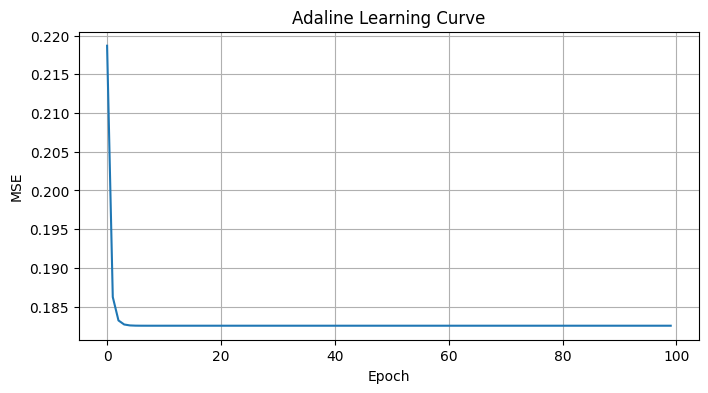

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(model.mse_history)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Adaline Learning Curve")
plt.grid(True)
plt.show()


- Biểu đồ của mô hình Adaline cho thấy sai số MSE giảm mạnh trong những epoch đầu tiên(cột dọc). Sau khoảng một vài epoch, giá trị MSE gần như ổn định và không giảm đáng kể => mô hình đã hội tụ => thuật toán Adaline đã học được mối quan hệ giữa các đặc trưng môi trường như độ ẩm đất, nhiệt độ, thời gian và lượng mưa để dự đoán nhu cầu tưới cây

## 6. Đánh giá mô hình


In [95]:
# Đánh giá mô hình

test_pred = model.predict(X_test)

mse = np.mean((t_test - test_pred)**2)

print("Test MSE:", mse)

errors = np.abs(t_test - test_pred)

largest = np.argsort(errors)[-3:]

print("\nCác mẫu sai số lớn:")
for i in largest:
    print(
        "Thực tế:", t_test[i],
        "Dự đoán:", round(test_pred[i],4),
        "Sai số:", round(errors[i],4)
    )

print("\nPhân tích trọng số:")
for f, w in zip(features, model.w):
    if w > 0:
        print(f"{f}: tăng nhu cầu tưới")
    else:
        print(f"{f}: giảm nhu cầu tưới")


Test MSE: 0.18724331954083864

Các mẫu sai số lớn:
Thực tế: 0.0 Dự đoán: 0.9008 Sai số: 0.9008
Thực tế: 1.0 Dự đoán: 0.017 Sai số: 0.983
Thực tế: 1.0 Dự đoán: -0.0438 Sai số: 1.0438

Phân tích trọng số:
Soil Moisture: giảm nhu cầu tưới
Temperature: tăng nhu cầu tưới
Time: giảm nhu cầu tưới
rainfall: giảm nhu cầu tưới


## 7. Chọn ngưỡng và thử nghiệm (thêm data thực nghiệm, thêm data k cần tưới)

Nếu cần một quyết định rời rạc (ví dụ cảnh báo/không cảnh báo) từ điểm liên tục, hãy chọn ngưỡng phù hợp và giải thích lựa chọn.

In [96]:
# Chuyển dự đoán liên tục thành quyết định tưới

threshold = 0.5

def watering_decision(value):
    if value >= threshold:
        return "CẦN TƯỚI - BẬT MÁY BƠM"
    return "CHƯA CẦN TƯỚI - TẮT MÁY BƠM"


# Thử dữ liệu mới
new_samples = np.array([
    [30, 35, 10, 0],
    [80, 28, 2, 70],
    [45, 32, 8, 20]
], dtype=float)

new_scaled = (new_samples - X_min)/(X_max-X_min)

predictions = model.predict(new_scaled)

for p in predictions:
    print(
        "Mức độ cần tưới:",
        round(max(0,min(1,p)),4),
        "=>",
        watering_decision(p)
    )


Mức độ cần tưới: 0.9702 => CẦN TƯỚI - BẬT MÁY BƠM
Mức độ cần tưới: 0.5938 => CẦN TƯỚI - BẬT MÁY BƠM
Mức độ cần tưới: 0.8454 => CẦN TƯỚI - BẬT MÁY BƠM


In [97]:
# ============================================================
# HÀM CHUẨN HÓA MIN-MAX
# ============================================================

def fit_minmax(X):
    min_value = X.min(axis=0)
    max_value = X.max(axis=0)

    scale = max_value - min_value
    scale[scale == 0] = 1.0

    return min_value, scale


def transform_minmax(X, min_value, scale):
    return (X - min_value) / scale

In [98]:
# Tạo lại min và scale từ dữ liệu train
min_value, scale = fit_minmax(X_train)

# Chuẩn hóa dữ liệu train
X_train_scaled = transform_minmax(
    X_train,
    min_value,
    scale
)

# Chuẩn hóa dữ liệu test
X_test_scaled = transform_minmax(
    X_test,
    min_value,
    scale
)

In [99]:
# ============================================================
# THỰC NGHIỆM NHIỀU TRƯỜNG HỢP
# ============================================================

experimental_data = pd.DataFrame([
    # Nhóm CẦN TƯỚI
    [25, 35, 12, 0,  "Cần tưới"],
    [30, 34, 10, 5,  "Cần tưới"],
    [35, 36, 14, 0,  "Cần tưới"],
    [40, 33, 9,  2,  "Cần tưới"],

    # Nhóm CHƯA CẦN TƯỚI
    [75, 28, 2,  60, "Chưa cần tưới"],
    [80, 27, 1,  80, "Chưa cần tưới"],
    [70, 29, 3,  50, "Chưa cần tưới"],
    [85, 26, 1,  70, "Chưa cần tưới"],
], columns=[
    "Soil Moisture",
    "Temperature",
    "Time",
    "rainfall",
    "Điều kiện thực tế"
])

experimental_data

,Soil Moisture,Temperature,Time,rainfall,Điều kiện thực tế
0,25,35,12,0,Cần tưới
1,30,34,10,5,Cần tưới
2,35,36,14,0,Cần tưới
3,40,33,9,2,Cần tưới
4,75,28,2,60,Chưa cần tưới
5,80,27,1,80,Chưa cần tưới
6,70,29,3,50,Chưa cần tưới
7,85,26,1,70,Chưa cần tưới


## 8. Kết luận

- Việc sử dụng Adaline thay cho Perceptron giúp hệ thống không chỉ đưa ra quyết định bật/tắt máy bơm mà còn có thể biểu diễn mức độ cần nước thông qua giá trị liên tục, phù hợp hơn với bài toán thực tế, áp dụng để thay thế phương pháp Perceptron nhằm cải thiện khả năng dự đoán. Adaline giúp hệ thống có khả năng mở rộng trong tương lai, ví dụ như điều chỉnh lượng nước hoặc thời gian tưới thay vì chỉ quyết định bật hoặc tắt máy bơm.

- Kết quả cho thấy Adaline phù hợp hơn với bài toán này vì có khả năng học giá trị liên tục thay vì chỉ phân loại hai trạng thái.Tuy nhiên, do Adaline là mô hình tuyến tính nên vẫn còn hạn chế khi xử lý các mối quan hệ phức tạp giữa điều kiện môi trường và nhu cầu nước của cây.